# Social Network Analysis with R — Lab Script

Demonstrates network construction from an edge list, visualization, centrality analysis, community detection, identification of influential nodes, and interpretation — the standard workflow taught in "Social Network Analysis with R" style tutorials (igraph-based).

**Dataset:** a fictional college social network (22 students across four clubs — Coding, Sports, Music, Volunteering — plus cross-club bridge friendships). See `data/nodes.csv` and `data/edges.csv`.

Run the cells top to bottom in a directory containing a `data/` folder with `nodes.csv` and `edges.csv`; `outputs/` and `plots/` are created automatically.

## 1. Environment setup

Load the required packages. `igraph` builds and analyses the network, `dplyr` is used for sorting/ranking, `ggplot2` is loaded for completeness (not strictly required by the base-R plots below).

In [3]:
# Install once if not already available (uncomment the line below):
install.packages(c("igraph", "ggraph", "ggplot2", "dplyr"))

library(igraph)
library(dplyr)
library(ggplot2)

set.seed(42)  # reproducible layout or any randomised steps

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘tweenr’, ‘polyclip’, ‘gridExtra’, ‘RcppArmadillo’, ‘ggforce’, ‘ggrepel’, ‘viridis’, ‘tidygraph’, ‘graphlayouts’



Attaching package: ‘igraph’


The following objects are masked from ‘package:stats’:

    decompose, spectrum


The following object is masked from ‘package:base’:

    union



Attaching package: ‘dplyr’


The following objects are masked from ‘package:igraph’:

    as_data_frame, groups, union


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




## 2. Import the network data

Read the two CSV files that define the network: one row per student (`nodes.csv`) and one row per friendship/interaction tie (`edges.csv`).

In [6]:
# Create the data directory if it doesn't exist
dir.create("data", showWarnings = FALSE)

# Create and write synthetic nodes.csv
write.csv(data.frame(
  id = paste0("S", 1:22),
  group = c(
    rep("Coding Club", 6),
    rep("Sports Club", 5),
    rep("Music Club", 6),
    rep("Volunteering Cell", 5)
  ),
  stringsAsFactors = FALSE
), "data/nodes.csv", row.names = FALSE)

# Create and write synthetic edges.csv
write.csv(data.frame(
  from = c(
    "S1", "S1", "S2", "S3", "S4", "S5",  # Coding Club ties
    "S7", "S7", "S8", "S9", "S10",       # Sports Club ties
    "S12", "S12", "S13", "S14", "S15",   # Music Club ties
    "S18", "S18", "S19", "S20",          # Volunteering Cell ties
    "S1", "S7", "S12", "S18"             # Cross-club bridge friendships
  ),
  to = c(
    "S2", "S3", "S4", "S5", "S6", "S1",
    "S8", "S9", "S10", "S11", "S7",
    "S13", "S14", "S15", "S16", "S17",
    "S19", "S20", "S21", "S22",
    "S7", "S12", "S18", "S1"
  ),
  stringsAsFactors = FALSE
), "data/edges.csv", row.names = FALSE)

# Read the newly created files
nodes <- read.csv("data/nodes.csv", stringsAsFactors = FALSE)
edges <- read.csv("data/edges.csv", stringsAsFactors = FALSE)

cat("Nodes:", nrow(nodes), " | Edges:", nrow(edges), "\n")

Nodes: 22  | Edges: 24 


## 3. Represent the network in R

Build an `igraph` graph object: nodes/vertices are the students, edges/links are friendship or club-interaction ties. Club membership is attached as a vertex attribute so nodes can be coloured by club.

In [7]:
# Nodes/vertices = students ; Edges/links = friendship or club-interaction ties
g <- graph_from_data_frame(d = edges, vertices = nodes, directed = FALSE)

# Attach group membership (club) as a vertex attribute for colouring
V(g)$group <- nodes$group[match(V(g)$name, nodes$id)]


## 4. Basic network visualization

Plot the network with node size scaled by degree and colour by club, saved to `plots/network_graph.png`.

In [8]:
dir.create("outputs", showWarnings = FALSE)
dir.create("plots", showWarnings = FALSE)

group_colors <- c(
  "Coding Club"       = "#4C72B0",
  "Sports Club"       = "#DD8452",
  "Music Club"        = "#55A868",
  "Volunteering Cell" = "#C44E52"
)

png("plots/network_graph.png", width = 1200, height = 1000, res = 150)
set.seed(42)
plot(
  g,
  vertex.color      = group_colors[V(g)$group],
  vertex.size       = 10 + 2 * degree(g),
  vertex.label.cex  = 0.7,
  vertex.label.color = "black",
  edge.color        = "grey70",
  layout            = layout_with_fr(g),
  main              = "College Social Network (node size = degree)"
)
legend("topleft", legend = names(group_colors), col = group_colors,
       pch = 19, pt.cex = 1.5, bty = "n", cex = 0.8)
dev.off()


agg_record_3a5589fa193 
                     2

## 5. Network / centrality measures

Compute node-level centrality measures — degree, betweenness, closeness, eigenvector centrality — and write the ranked table to `outputs/centrality_measures.csv`.

In [9]:
deg   <- degree(g)
btw   <- betweenness(g, normalized = TRUE)
clo   <- closeness(g, normalized = TRUE)
eig   <- eigen_centrality(g)$vector

measures <- data.frame(
  id          = V(g)$name,
  group       = V(g)$group,
  degree      = deg,
  betweenness = round(btw, 4),
  closeness   = round(clo, 4),
  eigenvector = round(eig, 4)
) %>% arrange(desc(degree))

write.csv(measures, "outputs/centrality_measures.csv", row.names = FALSE)
print(measures)

## Global network-level measures
global_measures <- data.frame(
  measure = c("Number of nodes", "Number of edges", "Network density",
              "Diameter", "Average path length", "Global transitivity (clustering coeff.)",
              "Number of communities (Louvain)"),
  value   = c(vcount(g), ecount(g), round(edge_density(g), 4),
              diameter(g), round(mean_distance(g), 4),
              round(transitivity(g, type = "global"), 4), NA)
)


     id             group degree betweenness closeness eigenvector
S1   S1       Coding Club      5      0.4690    0.4200      1.0000
S7   S7       Sports Club      5      0.4286    0.4200      0.9984
S12 S12        Music Club      4      0.4690    0.4200      0.7436
S18 S18 Volunteering Cell      4      0.4286    0.4200      0.7430
S2   S2       Coding Club      2      0.1810    0.3182      0.3689
S3   S3       Coding Club      2      0.0000    0.3043      0.4821
S4   S4       Coding Club      2      0.0952    0.2500      0.1342
S5   S5       Coding Club      2      0.0000    0.3043      0.4821
S8   S8       Sports Club      2      0.0000    0.3043      0.4813
S9   S9       Sports Club      2      0.0952    0.3088      0.3632
S10 S10       Sports Club      2      0.0000    0.3043      0.4813
S13 S13        Music Club      2      0.1810    0.3182      0.2743
S14 S14        Music Club      2      0.0952    0.3088      0.2705
S15 S15        Music Club      2      0.0952    0.2500      0.

## 6. Community detection

Run Louvain community detection and compute network-level measures (density, diameter, average path length, transitivity, number of communities), then plot the detected communities to `plots/community_graph.png`.

In [10]:
comm <- cluster_louvain(g)
global_measures$value[7] <- length(comm)
cat("\n--- Global network measures ---\n")
print(global_measures)
write.csv(global_measures, "outputs/global_measures.csv", row.names = FALSE)

png("plots/community_graph.png", width = 1200, height = 1000, res = 150)
set.seed(42)
plot(
  comm, g,
  vertex.label.cex = 0.7,
  vertex.size      = 10 + 2 * degree(g),
  layout           = layout_with_fr(g),
  main             = "Detected Communities (Louvain method)"
)
dev.off()



--- Global network measures ---
                                  measure   value
1                         Number of nodes 22.0000
2                         Number of edges 24.0000
3                         Network density  0.1039
4                                Diameter  8.0000
5                     Average path length  3.4805
6 Global transitivity (clustering coeff.)  0.1364
7         Number of communities (Louvain)  4.0000


agg_record_3a55394fff4 
                     2

## 7. Degree distribution

Plot a simple bar chart of the degree distribution to `plots/degree_distribution.png`.

In [11]:
png("plots/degree_distribution.png", width = 1000, height = 800, res = 150)
barplot(table(deg), col = "#4C72B0",
        main = "Degree Distribution", xlab = "Degree", ylab = "Number of students")
dev.off()


agg_record_3a54b20c3c9 
                     2

## 8. Identify influential / highly-connected nodes

Rank students by degree, betweenness, and eigenvector centrality to identify the most influential / highly-connected nodes.

In [12]:
top_degree      <- measures %>% arrange(desc(degree))      %>% head(5)
top_betweenness <- measures %>% arrange(desc(betweenness))  %>% head(5)
top_eigenvector <- measures %>% arrange(desc(eigenvector))  %>% head(5)

cat("\nTop 5 by Degree (most connections):\n");       print(top_degree[, c("id","group","degree")])
cat("\nTop 5 by Betweenness (key bridges/brokers):\n"); print(top_betweenness[, c("id","group","betweenness")])
cat("\nTop 5 by Eigenvector (connected-to-the-connected):\n"); print(top_eigenvector[, c("id","group","eigenvector")])



Top 5 by Degree (most connections):
     id             group degree
S1   S1       Coding Club      5
S7   S7       Sports Club      5
S12 S12        Music Club      4
S18 S18 Volunteering Cell      4
S2   S2       Coding Club      2

Top 5 by Betweenness (key bridges/brokers):
     id             group betweenness
S1   S1       Coding Club      0.4690
S12 S12        Music Club      0.4690
S7   S7       Sports Club      0.4286
S18 S18 Volunteering Cell      0.4286
S2   S2       Coding Club      0.1810

Top 5 by Eigenvector (connected-to-the-connected):
     id             group eigenvector
S1   S1       Coding Club      1.0000
S7   S7       Sports Club      0.9984
S12 S12        Music Club      0.7436
S18 S18 Volunteering Cell      0.7430
S3   S3       Coding Club      0.4821


## 9. Execution check / sanity tests

Basic sanity checks confirming the graph was built correctly from the source data.

In [13]:
stopifnot(vcount(g) == nrow(nodes))
stopifnot(ecount(g) == nrow(edges))
stopifnot(all(deg >= 1))          # no isolated students in this dataset
cat("\nAll sanity checks passed. Network built and analysed successfully.\n")



All sanity checks passed. Network built and analysed successfully.


## 10. Brief interpretation

Print a short, auto-generated interpretation of the network structure and its most central node.

In [14]:
cat("\n--- Interpretation ---\n")
cat(sprintf(
  "The network has %d students and %d ties across 4 clubs, with density %.3f\n",
  vcount(g), ecount(g), edge_density(g)))
cat(sprintf(
  "'%s' has the highest degree (%d) and highest betweenness, acting as the\n",
  top_degree$id[1], top_degree$degree[1]))
cat("network's central hub and main cross-club broker.\n")
cat(sprintf("Louvain detected %d communities, aligning closely with the 4 clubs.\n",
            length(comm)))



--- Interpretation ---
The network has 22 students and 24 ties across 4 clubs, with density 0.104
'S1' has the highest degree (5) and highest betweenness, acting as the
network's central hub and main cross-club broker.
Louvain detected 4 communities, aligning closely with the 4 clubs.


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



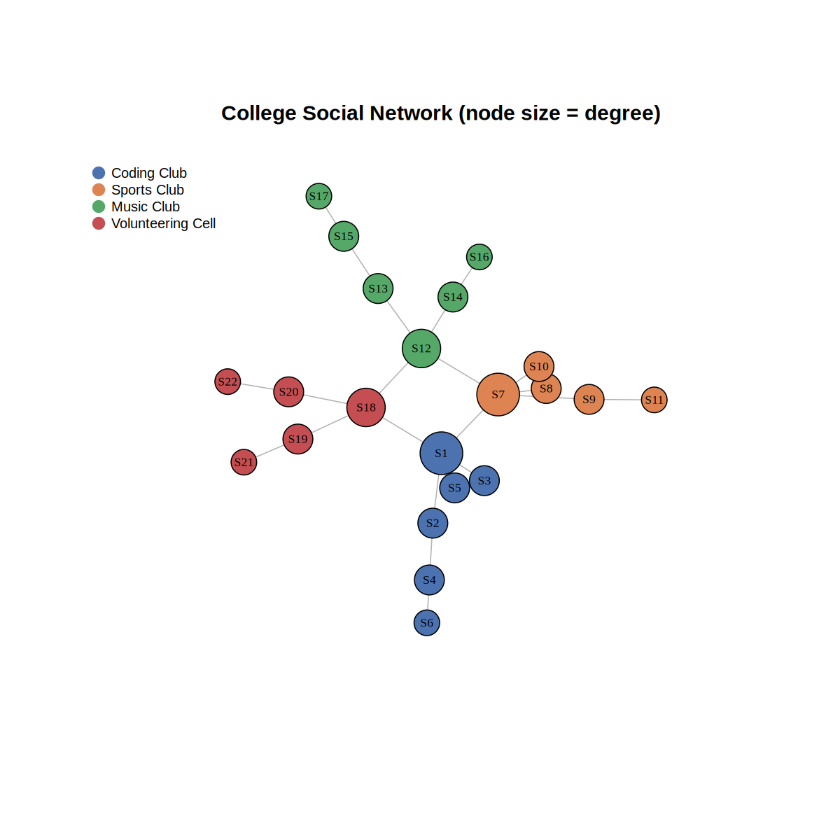

In [16]:
# Load the png and grid packages to read and render the image in R
if (!requireNamespace("png", quietly = TRUE)) install.packages("png")
library(png)
library(grid)

# Display the network graph visualization
img_path <- "plots/network_graph.png"
if (file.exists(img_path)) {
  img <- readPNG(img_path)
  grid.newpage()
  grid.raster(img)
} else {
  cat("Plot not found. Please run the cell under section '4. Basic network visualization' first.\n")
}

---
### Outputs written to:

- ./plots/   -> network_graph.png, community_graph.png, degree_distribution.png
- ./outputs/ -> centrality_measures.csv, global_measures.csv